1. Import libraries

In [ ]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy as sc
import sklearn as skl
import keras as k
import tensorflow as tf
import scipy.io
import os
import io
import shutil
import glob
import time
import h5py

print('Libraries have been imported successfully')

Libraries have been imported successfully


2. Structure the data and move them to the respective folder

In [ ]:
# create folders and subfolders
your_path_start = (r'/content')
new_folder_RAW_DATASET_CNN = "RAW_DATASET_CNN"
path_DATASET = os.path.join(your_path_start, new_folder_RAW_DATASET_CNN)
os.mkdir(path_DATASET)

your_path = (r'/content/RAW_DATASET_CNN')
new_folder_sorted_DA = "DA_sorted"
new_folder_sorted_OA = "OA_sorted"
new_folder_DA = "DA"
new_folder_OA = "OA"
path_OA_sorted = os.path.join(your_path, new_folder_sorted_DA)
os.mkdir(path_OA_sorted)
path_DA_sorted = os.path.join(your_path, new_folder_sorted_OA)
os.mkdir(path_DA_sorted)
path_OA = os.path.join(your_path, new_folder_DA)
os.mkdir(path_OA)
path_DA = os.path.join(your_path, new_folder_OA)
os.mkdir(path_DA)

# for the val set that is needed later
new_folder_sorted_DA = "DA_val_sorted"
new_folder_sorted_OA = "OA_val_sorted"

path_OA_val_sorted = os.path.join(your_path, new_folder_sorted_DA)
os.mkdir(path_OA_val_sorted)
path_DA_val_sorted = os.path.join(your_path, new_folder_sorted_OA)
os.mkdir(path_DA_val_sorted)

print('The following folders have been created: RAW_DATASET_CNN, DA_sorted, OA_sorted, DA, OA and also DA_val_sorted, OA_val_sorted')

The following folders have been created: RAW_DATASET_CNN, DA_sorted, OA_sorted, DA, OA and also DA_val_sorted, OA_val_sorted


####--------  Upload data  --------

####Now you have to upload the data to this Colab!

/oa/ files in OA folder and /da/ files in DA folder!

2 Options:
- either use "RAW_DATASET_CNN_without_Val_data", which already excluded the validation data (9 participants: last 5 /da/ and last 4 /oa/ participants)

- or keep different participants for the validation later - so just upload the ones you want, and use the other ones later as unseen data. For this option you should use this folder: "RAW_DATASET_CNN"


[Additional info for cross-validation: Depending on how many folds you choose, your train/test set will vary.
For a split such as: Train(67%), Test(23%) and Validation(10%), please upload the data of ALL participants, except 9 with a foldnumber of 4]

In [ ]:
def list_participants(stimulus_used_in_capital_letters, first_characters_of_files, remove_first_x_characters, keep_x_characters):
  '''gives a list of all participants for one of the stimuli (stimulus_used) extracting the middle part (characters 6+7+8) of the name of the file,
    that all the files of one partipcipant have in common. For example: PH02_001_NNBA60A.4 -> will give 001'''

  list_DA = []
  os.chdir(r'/content/RAW_DATASET_CNN/{}'.format(stimulus_used_in_capital_letters))
  for file in glob.glob('{}*'.format(first_characters_of_files)): # find all files that start with 'first_characters_of_files'
    list_DA.append(file)
  list_new =[]
  z = (keep_x_characters + remove_first_x_characters)
  for item in list_DA:
    list_new.append(item[:z]) # keep only z characters
  list_new2 =[]
  for item in list_new:
    list_new2.append(item[remove_first_x_characters:]) # remove first 5 characters of string in list
  foldernumber = list(set(list_new2)) # to eliminate duplicates
  foldernumber.sort()
  print('A list for each participant with the entered stimulus has been created.')
  return foldernumber

foldernumber_DA = list_participants(stimulus_used_in_capital_letters = 'DA', first_characters_of_files= 'PH02_', remove_first_x_characters = 5, keep_x_characters = 3)
foldernumber_OA = list_participants(stimulus_used_in_capital_letters = 'OA', first_characters_of_files= 'PH02_', remove_first_x_characters = 5, keep_x_characters = 3)
print('There are {} participants for the OA stimulus.'.format(len(foldernumber_OA)))
print('There are {} participants for the DA stimulus.'.format(len(foldernumber_DA)))

def create_subfolders(list_of_participants, stimulus_used_in_capital_letters, prefix_of_subfolder_name):
  '''folder 'stimulus'_sorted will be created for the stimulus used,
    in this folder there will be subfolders created with your chosen name (prefix_of_subfolder_name)
    + the characters of your list of participants (name_of_list) from the function above.
    For example here: 'OA_PH02_' + 001, 'OA_PH02_' + 003, ..'''

  your_path = (r'/content/RAW_DATASET_CNN/{}_sorted'.format(stimulus_used_in_capital_letters))
  for i in range(len(list_of_participants)):
    new_folder = "{}{}".format(prefix_of_subfolder_name, list_of_participants[i].format(stimulus_used_in_capital_letters))
    path_new_folder = os.path.join(your_path, new_folder)
    os.mkdir(path_new_folder)
  print('Participant-specific subfolders for stimulus "{}" have been created successfully.'.format(stimulus_used_in_capital_letters))
  return

create_subfolders(list_of_participants = foldernumber_DA, stimulus_used_in_capital_letters = 'DA', prefix_of_subfolder_name = 'DA_PH02_')
create_subfolders(list_of_participants = foldernumber_OA, stimulus_used_in_capital_letters = 'OA', prefix_of_subfolder_name = 'OA_PH02_')


A list for each participant with the entered stimulus has been created.
A list for each participant with the entered stimulus has been created.
There are 30 participants for the OA stimulus.
There are 47 participants for the DA stimulus.
Participant-specific subfolders for stimulus "DA" have been created successfully.
Participant-specific subfolders for stimulus "OA" have been created successfully.


In [ ]:
# move the files into the respective subfolders

#find all files with the same 3 numbers and move them to the created folder with the same name
list_of_filenames_DA = []
for i in range(len(foldernumber_DA)):
  change = foldernumber_DA[i] # change = '002', '004', etc
  if change in "PH02_{}­".format(change): # only if substring eg. '002' exists, do the next step

    os.chdir('/content/RAW_DATASET_CNN/DA')
    for file in glob.glob('PH02_{}*'.format(change)):
      list_of_filenames_DA.append('{}'.format(file))

      src_path_DA = '/content/RAW_DATASET_CNN­/DA/{}'.format(file)
      src_path_DA = src_path_DA.replace('\xad', '')

      dst_path_DA = "/content/RAW_DATASET_CNN/DA_sorted/DA_PH02_{}/{}".format(change, file) #.format(change, file) # move to the respective subfolder eg. '002'
      dst_path_DA = dst_path_DA.replace('\xad', '')
      #print(file, 'will be moved to folder: DA_PH02_{}'.format(change))

      shutil.move(src_path_DA,dst_path_DA)
      # files from the folder DA are moved to folder DA_sorted + in its specific subfolder
print('DA files have been moved into the respective subfolders.')


#do the same as above for OA
list_of_filenames_OA = []
for i in range(len(foldernumber_OA)):
  change = foldernumber_OA[i] # change = '001', '003', etc
  if change in "PH02_{}­".format(change): # only if substring eg. '001' exists, do the next step ##WHILE???


    os.chdir('/content/RAW_DATASET_CNN/OA')
    for file in glob.glob('PH02_{}*'.format(change)):
      list_of_filenames_OA.append('{}'.format(file))

      src_path_OA = '/content/RAW_DATASET_CNN­/OA/{}'.format(file)
      src_path_OA = src_path_OA.replace('\xad', '')

      dst_path_OA = "/content/RAW_DATASET_CNN/OA_sorted/OA_PH02_{}/{}".format(change, file) #.format(change, file) # move to the respective subfolder eg. '002'
      dst_path_OA = dst_path_OA.replace('\xad', '')
      #print(file, 'will be moved to folder: OA_PH02_{}'.format(change))

      shutil.move(src_path_OA,dst_path_OA)
      # files from the folder DA are moved to folder DA_sorted + in its specific subfolder
print('OA files have been moved into the respective subfolders.')

DA files have been moved into the respective subfolders.
OA files have been moved into the respective subfolders.


3. Adding labels to the data (/da/ and /oa/)

In [ ]:
# open each of the files and put it in a format (data frame)that one can work with and add the respective labels oa, da
frames_OA = []

for i in range(len(foldernumber_OA)):
  change = foldernumber_OA[i] # change = '001', '003', etc
  if change in "PH02_{}­".format(change):
    os.chdir(r'/content/RAW_DATASET_CNN/OA_sorted/OA_PH02_{}'.format(change))
    subfolder_OA_path = (r'/content/RAW_DATASET_CNN/OA_sorted/OA_PH02_{}'.format(change))
    for file in glob.glob('PH02_{}*'.format(change)):

      # open the mat files inside the subfolders
      mat = scipy.io.loadmat(subfolder_OA_path + '/' + file) # loads the .mat file from the Colab folder into this notebook
      sorted(mat.keys()) # the .mat file stores data as a dictionary and the matrix can be found in 'a'
      #print('The mat file {} contains: '.format(file), mat.keys())
      matrix = mat['matrix_data'] # the dictionary entry 'matrix_data' is assigned to the name matrix

# convert to a pandas dataframe
      matrix_np = np.array(matrix) # conversion to an numpy array
      df_OA = pd.DataFrame(matrix_np) # convert numpy array to pandas dataframe

# add a label
      def add_label(output_list, stimulus_used, dataset, number_of_rows):
        ''' add a column with labels to the dataset'''

        my_list = list(range(number_of_rows))
        for i in range(len(my_list)):
          my_list[i] = stimulus_used

        dataset['stimulus'] = my_list
        output_list.append(dataset)
        return

      add_label(output_list = frames_OA, stimulus_used = '0', dataset = df_OA, number_of_rows = 40)
print('All /oa/ labels (0) have been added successfully')

### Repeat for DA
frames_DA = []
for i in range(len(foldernumber_DA)):
  change = foldernumber_DA[i] # change = '001', '003', etc
  if change in "PH02_{}­".format(change):
    os.chdir(r'/content/RAW_DATASET_CNN/DA_sorted/DA_PH02_{}'.format(change))
    subfolder_DA_path = (r'/content/RAW_DATASET_CNN/DA_sorted/DA_PH02_{}'.format(change))
    for file in glob.glob('PH02_{}*'.format(change)):

      # open the mat files inside the subfolders
      mat = scipy.io.loadmat(subfolder_DA_path + '/' + file) # loads the .mat file from the Colab folder into this notebook
      sorted(mat.keys()) # the .mat file stores data as a dictionary and the matrix can be found in 'a'
      matrix = mat['matrix_data'] # the dictionary entry 'matrix_data' is assigned to the name matrix

# convert to a pandas dataframe
      matrix_np = np.array(matrix) # conversion to an numpy array
      df_DA = pd.DataFrame(matrix_np) # convert numpy array to pandas dataframe

# add a label
      add_label(output_list = frames_DA, stimulus_used = '1', dataset = df_DA, number_of_rows = 40)
print('All /da/ labels (1) have been added successfully')

All /oa/ labels (0) have been added successfully
All /da/ labels (1) have been added successfully


4. Merging data frames of individual files to one large data frame

In [ ]:
# concatenate the single dataframes to one for OA
merged_df_OA = pd.concat(frames_OA, keys = list_of_filenames_OA)
print('Shape of the merged OA data frame is:', merged_df_OA.shape)

# concatenate the single dataframes to one for DA
merged_df_DA = pd.concat(frames_DA, keys = list_of_filenames_DA)
print('Shape of the merged DA data frame is:', merged_df_DA.shape)

# optional: truncate DA samples to have a balanced data set if needed
# same_size = merged_df_DA.shape[0] - merged_df_OA.shape[0]
# merged_df_DA = merged_df_DA[:-same_size]

# concatenate both (OA and DA) data frames into one final data frame and again convert to Pandas data frame
frames_both = [merged_df_OA, merged_df_DA] # creating a list, as this is needed as input for the pd.concat function

final_df = pd.concat(frames_both, keys = ['OA', 'DA'])
print('The two data frames have been successfully merged.')
print('Shape of the final data frame is:', final_df.shape)

final_df = pd.DataFrame(final_df) # convert numpy array to pandas data frame

Shape of the merged OA data frame is: (4800, 4097)
Shape of the merged DA data frame is: (7520, 4097)
The two data frames have been successfully merged.
Shape of the final data frame is: (12320, 4097)


5. Ensure that all data is inside the final data frame

In [ ]:
# convert again to pandas data frame and ensure that all the data is in the final data frame

final_df = pd.DataFrame(final_df) # convert numpy array to pandas dataframe (we stored the matrices as a list, therefore we lost the convertion from before)

print('The shape of the merged data frame is:', final_df.shape)
print('Number of participants (OA trials):', len(foldernumber_OA), '->',  len(foldernumber_OA), 'x 40 rows x 4 files per participant =', len(foldernumber_OA)*40*4)
print('Number of participants (DA trials):', len(foldernumber_DA), '->',  len(foldernumber_DA), 'x 40 rows x 4 files per participant =', len(foldernumber_DA)*40*4)
print('Sum:', (len(foldernumber_OA)*40*4) + (len(foldernumber_DA)*40*4))

# drop columns number: 3604-4095 (not number 4096 as it is the label)
# as the last columns of the /da/ data has only zeros,
# and the ML algorithm will otherwise focus on that instead of actually learning features
for i in range(3605,4096):
  final_df = final_df.drop([i], axis=1)

print('Length of each row has been shortened successfully.')
print('Shape of the final dataset is:', final_df.shape)

The shape of the merged data frame is: (12320, 4097)
Number of participants (OA trials): 30 -> 30 x 40 rows x 4 files per participant = 4800
Number of participants (DA trials): 47 -> 47 x 40 rows x 4 files per participant = 7520
Sum: 12320
Length of each row has been shortened successfully.
Shape of the final dataset is: (12320, 3606)


6. Create X and y (data and labels)

In [ ]:
# Create X (all columns except the label column called 'stimulus')
X = final_df.drop("stimulus", axis=1)
# Create y (only the label column called 'stimulus')
y = final_df["stimulus"]

7. Import libraries to create the model

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from keras.layers import Dense, Flatten, Convolution1D, Dropout, AveragePooling1D
from keras import metrics
from IPython.display import SVG
from keras.utils.vis_utils import model_to_dot
from sklearn.model_selection import KFold
from tensorflow.keras.layers import BatchNormalization
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

8. Create the model

The input shape is: (12320, 3605, 1)
Training for fold 1 ...
Model: "sequential"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d (Conv1D)                             (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization (BatchNormalization)    (None, 3605, 32)                        128            
                                                                                                    
 conv1d_1 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_1 (BatchNormalization)  (None, 3605, 64)                        256            
          

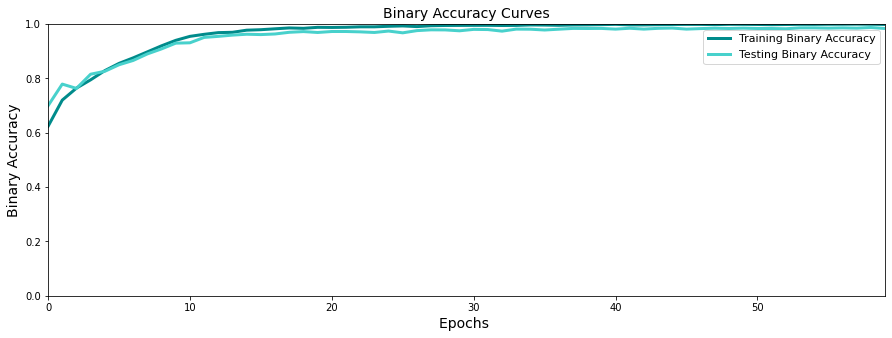

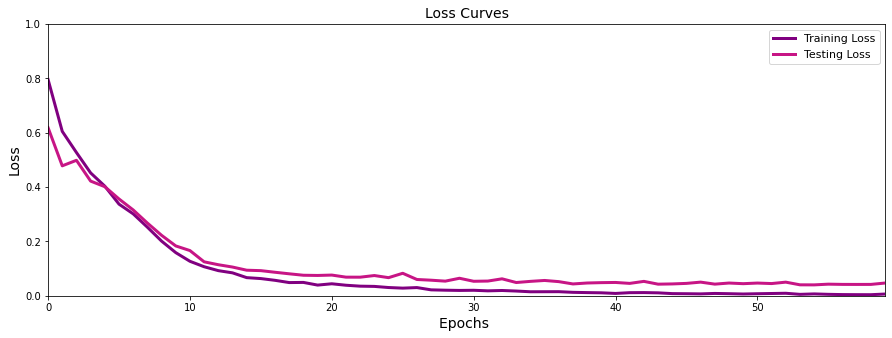

Training for fold 2 ...
Model: "sequential_1"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_4 (Conv1D)                           (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization_7 (BatchNormalization)  (None, 3605, 32)                        128            
                                                                                                    
 conv1d_5 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_8 (BatchNormalization)  (None, 3605, 64)                        256            
                                             

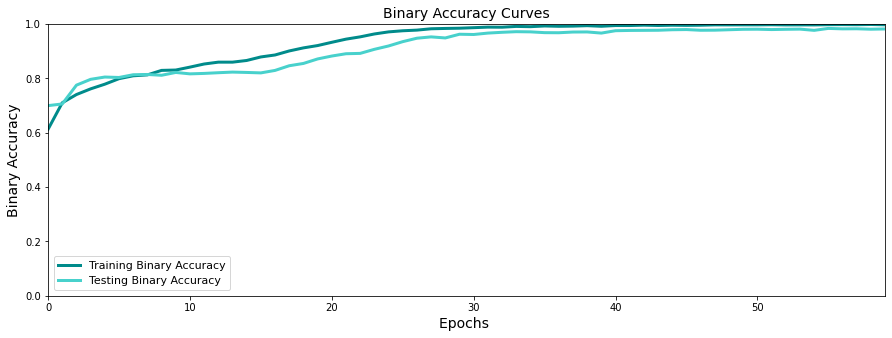

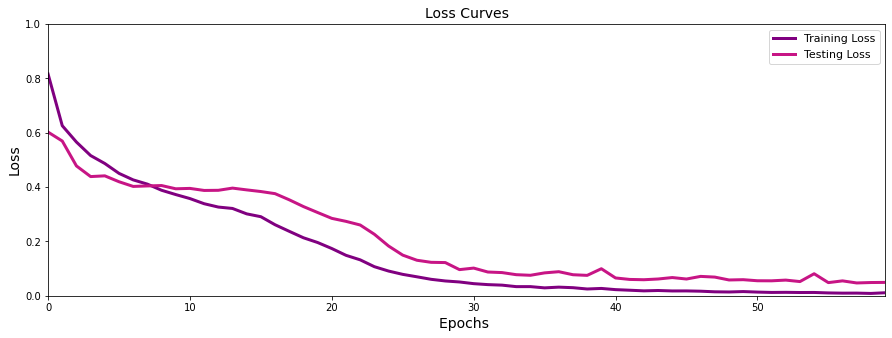

Training for fold 3 ...
Model: "sequential_2"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_8 (Conv1D)                           (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization_14 (BatchNormalization)  (None, 3605, 32)                       128            
                                                                                                    
 conv1d_9 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_15 (BatchNormalization)  (None, 3605, 64)                       256            
                                             

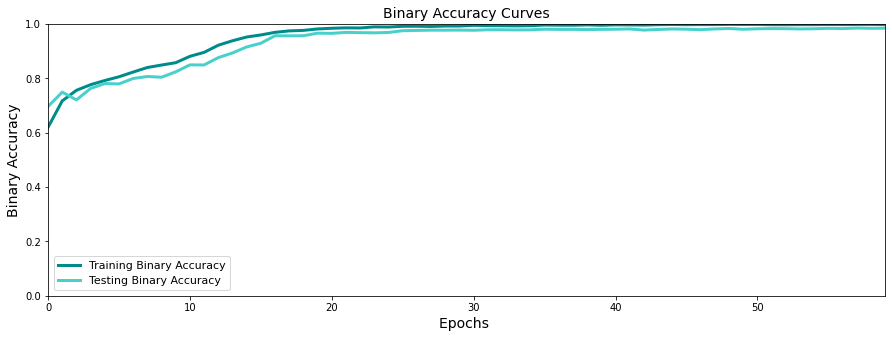

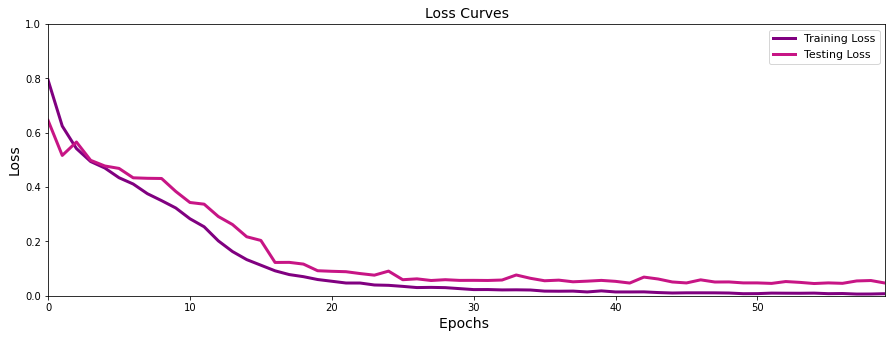

Training for fold 4 ...
Model: "sequential_3"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_12 (Conv1D)                          (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization_21 (BatchNormalization)  (None, 3605, 32)                       128            
                                                                                                    
 conv1d_13 (Conv1D)                          (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_22 (BatchNormalization)  (None, 3605, 64)                       256            
                                             

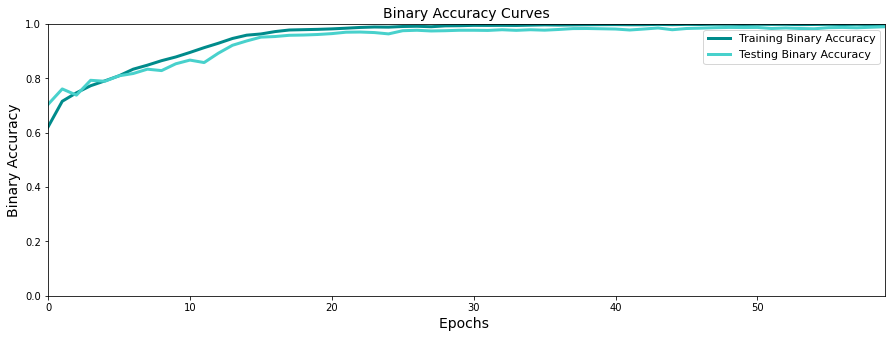

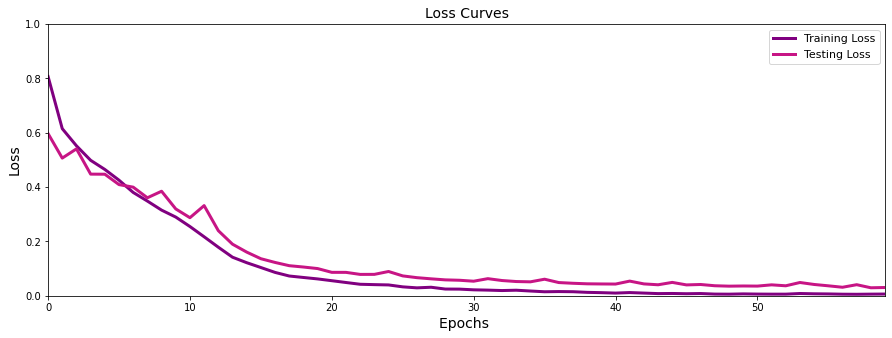

------------------------------------------------------------------------
Score per fold
------------------------------------------------------------------------
> Fold 1 Loss: 0.04695159196853638 | Precision: 0.9857969284057617 | Recall: 0.98735511302948 | Binary Accuracy: 0.9834415316581726
Accuracy: 0.0003246753185521811 | AUC: 0.9981377124786377 | False Neg: 27.0 | False Pos: 24.0
------------------------------------------------------------------------
> Fold 2 Loss: 0.049258679151535034 | Precision: 0.9906747341156006 | Recall: 0.9788618087768555 | Binary Accuracy: 0.9818181991577148
Accuracy: 0.0003246753185521811 | AUC: 0.9976528286933899 | False Neg: 17.0 | False Pos: 39.0
------------------------------------------------------------------------
> Fold 3 Loss: 0.04689985141158104 | Precision: 0.990296483039856 | Recall: 0.9839314222335815 | Binary Accuracy: 0.984415590763092
Accuracy: 0.002597402548417449 | AUC: 0.9981566667556763 | False Neg: 18.0 | False Pos: 30.0
-------------

In [ ]:
# 1D CNN model with K-fold cross validation

start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))
print('The input shape is:', inputs.shape)


# K-fold Cross Validation model evaluation
fold_no = 1
num_folds = 4 # here you can decide how many folds you want (in how many pieces the data is split)
epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

# define lists for storing the score values of the different folds
loss_per_fold = []
precision_per_fold = []
recall_per_fold = []
binary_accuracy_per_fold = []
accuracy_per_fold = []
AUC_per_fold = []
false_negatives_per_fold = []
false_positives_per_fold = []


# Define the K-fold Cross Validation
kfold = KFold(n_splits=num_folds, shuffle=True)

for train, test in kfold.split(inputs, targets):

  model = Sequential()

  model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
  model.add(BatchNormalization())
  model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
  model.add(BatchNormalization())
  model.add(Dropout(0.2))
  model.add(AveragePooling1D(pool_size=5))
  model.add(BatchNormalization())

  model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
  model.add(BatchNormalization())
  model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
  model.add(BatchNormalization())
  model.add(AveragePooling1D(pool_size=7))
  model.add(BatchNormalization())
  model.add(Dropout(0.2))

  model.add(Flatten())
  model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
  model.add(BatchNormalization())
  model.add(Dropout(0.5))
  model.add(Dense(units=1, activation='sigmoid'))

  model.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                loss='binary_crossentropy',
                metrics=[metrics.Precision(name='precision'),
                metrics.Recall(name='recall'),
                metrics.BinaryAccuracy(name='binary accuracy'),
                metrics.Accuracy(name='accuracy'),
                metrics.AUC(name='AUC'),
                metrics.FalsePositives(name='false positives'),
                metrics.FalseNegatives(name='false negatives')])

  print(f'Training for fold {fold_no} ...')
  model.summary(line_length = 100)

  print("Fit model on training data")

  history = model.fit(
      inputs[train],
      targets[train],
      batch_size=batch_size,
      epochs=epochs,
      verbose=1,
      validation_data=(inputs[test], targets[test])
  )

  # Generate generalization metrics
  fold_scores = model.evaluate(inputs[test], targets[test], verbose=0)
  print(f'''
  Test set scores for fold {fold_no}:
                            {model.metrics_names[0]} of {fold_scores[0]};
                            {model.metrics_names[1]} of {fold_scores[1]};
                            {model.metrics_names[2]} of {fold_scores[2]};
                            {model.metrics_names[3]} of {fold_scores[3]};
                            {model.metrics_names[4]} of {fold_scores[4]};
                            {model.metrics_names[5]} of {fold_scores[5]};
                            {model.metrics_names[6]} of {fold_scores[6]};
                            {model.metrics_names[7]} of {fold_scores[7]}

  ''')
  loss_per_fold.append(fold_scores[0])
  precision_per_fold.append(fold_scores[1])
  recall_per_fold.append(fold_scores[2])
  binary_accuracy_per_fold.append(fold_scores[3])
  accuracy_per_fold.append(fold_scores[4])
  AUC_per_fold.append(fold_scores[5])
  false_negatives_per_fold.append(fold_scores[6])
  false_positives_per_fold.append(fold_scores[7])


  # Plot the model 'binary accuracy' graph
  fig = plt.figure(figsize=(15,5))
  plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
  plt.plot(history.history['val_binary accuracy'],'mediumturquoise',linewidth=3.0, label='Testing Binary Accuracy')
  plt.legend(fontsize=11)
  plt.xlabel('Epochs ', fontsize=14)
  plt.ylabel('Binary Accuracy', fontsize=14)
  plt.title('Binary Accuracy Curves', fontsize=14)
  plt.ylim([0.0, 1.0])
  plt.xlim([0, epochs-1])
  plt.show()

  # Plot the model 'loss' graph
  fig = plt.figure(figsize=(15,5))
  plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
  plt.plot(history.history['val_loss'],'mediumvioletred',linewidth=3.0, label='Testing Loss')
  plt.legend(fontsize=11)
  plt.xlabel('Epochs ', fontsize=14)
  plt.ylabel('Loss', fontsize=14)
  plt.title('Loss Curves', fontsize=14)
  plt.ylim([0.0, 1.0])
  plt.xlim([0, epochs-1])
  plt.show()
  # Increase fold number
  fold_no = fold_no + 1

# == Provide average scores ==
print('------------------------------------------------------------------------')
print('Score per fold')
for i in range(0, len(accuracy_per_fold)):
  print('------------------------------------------------------------------------')
  print(f'> Fold {i+1} Loss: {loss_per_fold[i]} | Precision: {precision_per_fold[i]} | Recall: {recall_per_fold[i]} | Binary Accuracy: {binary_accuracy_per_fold[i]}')
  print(f'Accuracy: {accuracy_per_fold[i]} | AUC: {AUC_per_fold[i]} | False Neg: {false_negatives_per_fold[i]} | False Pos: {false_positives_per_fold[i]}')
print('------------------------------------------------------------------------')
print('Average scores for all folds:')
print(f'> Loss: {np.mean(loss_per_fold)}')
print(f'> Precision: {np.mean(precision_per_fold)}')
print(f'> Recall: {np.mean(recall_per_fold)}')
print(f'> Binary Accuracy: {np.mean(binary_accuracy_per_fold)} (+- {np.std(binary_accuracy_per_fold)})')
print(f'> Accuracy: {np.mean(accuracy_per_fold)} (+- {np.std(accuracy_per_fold)})')
print(f'> AUC: {np.mean(AUC_per_fold)}')
print(f'> False Neg: {np.mean(false_negatives_per_fold)}')
print(f'> False Pos: {np.mean(false_positives_per_fold)}')
print('------------------------------------------------------------------------')


end = time.time()
time_needed = int(end-start)

print('Running time for this model (for all folds): {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))


9. Train model on all data (train + test)

 [validation set is still excluded]

The input shape is: (12320, 3605, 1)
Model: "sequential"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d (Conv1D)                             (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization (BatchNormalization)    (None, 3605, 32)                        128            
                                                                                                    
 conv1d_1 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_1 (BatchNormalization)  (None, 3605, 64)                        256            
                                  

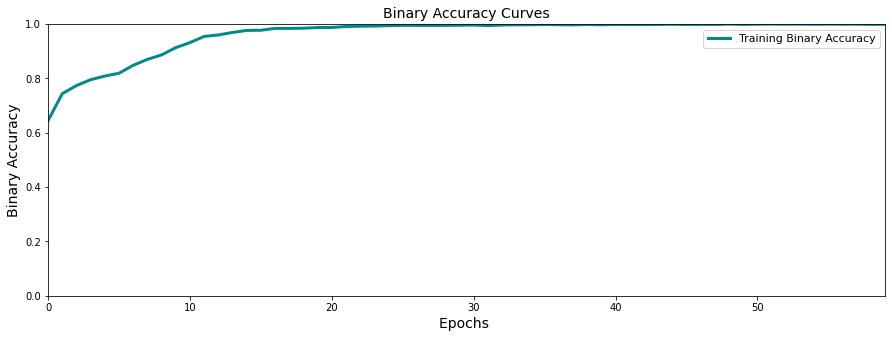

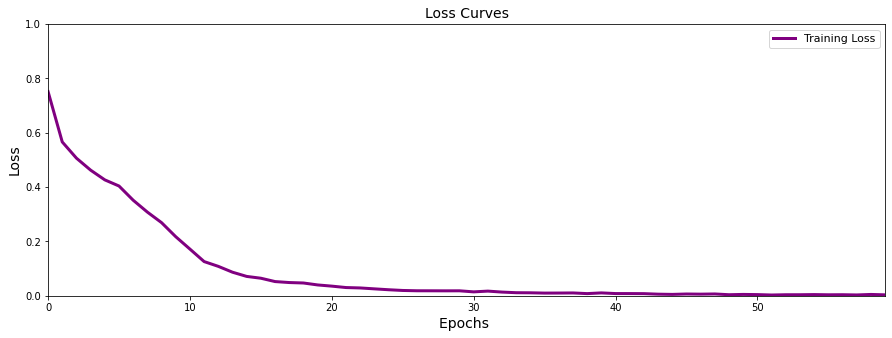

Running time for this model: 29 minute(s) and 30 second(s) (= 1770 seconds).


In [ ]:
# 1D CNN model training with all data (except val set)

start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))

print('The input shape is:', inputs.shape)

epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

model = Sequential()

model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
model.add(BatchNormalization())
model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(AveragePooling1D(pool_size=5))
model.add(BatchNormalization())

model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(AveragePooling1D(pool_size=7))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Flatten())
model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=[metrics.Precision(name='precision'),
              metrics.Recall(name='recall'),
              metrics.BinaryAccuracy(name='binary accuracy'),
              metrics.Accuracy(name='accuracy'),
              metrics.AUC(name='AUC'),
              metrics.FalsePositives(name='false positives'),
              metrics.FalseNegatives(name='false negatives')])

model.summary(line_length = 100)

print("Fit model on training data")

history = model.fit(
    inputs,
    targets,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1
)

# save the model and its weights
model.save('/content/my_saved_model.h5')

# Plot the model 'binary accuracy' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Binary Accuracy', fontsize=14)
plt.title('Binary Accuracy Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()

# Plot the model 'loss' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Loss Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()


end = time.time()
time_needed = int(end-start)

print('Running time for this model: {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))


10. Time to evaluate the final model on unseen data (Validation set)

10.1 Here you have 2 options:

a. Apply the method shown below to preprocess the data, so that it can be used as a data frame in this Colab (the same way it was done with the training data) to choose the participants that you have left outside the Colab until now or

b. Upload the files "X_Validation_9P.csv" and "y_Validation_9P.csv", which are the 9 participants that have already been preprocessed and are ready to use. (Participants number: 264, 281, 282, 297, 299 of /da/ and 133, 147, 148, 149 of /oa/)

In [ ]:
# OPTION a: Upload now (before running this cell!) OA and DA files from the participants that you haven't loaded to the Colab until now in the OA and DA folders (that you also used before)

foldernumber_DA = list_participants(stimulus_used_in_capital_letters = 'DA', first_characters_of_files= 'PH02_', remove_first_x_characters = 5, keep_x_characters = 3)
foldernumber_OA = list_participants(stimulus_used_in_capital_letters = 'OA', first_characters_of_files= 'PH02_', remove_first_x_characters = 5, keep_x_characters = 3)
print('There are {} participants for the DA stimulus.'.format(len(foldernumber_DA)))
print('There are {} participants for the OA stimulus.'.format(len(foldernumber_OA)))

def create_subfolders_for_val(list_of_participants, stimulus_used_in_capital_letters, prefix_of_subfolder_name):
  '''folder 'stimulus'_sorted will be created for the stimulus used,
    in this folder there will be subfolders created with your chosen name (prefix_of_subfolder_name)
    + the characters of your list of participants (name_of_list) from the function above.
    For example here: 'OA_PH02_' + 001, 'OA_PH02_' + 003, ..'''

  your_path = (r'/content/RAW_DATASET_CNN/{}_val_sorted'.format(stimulus_used_in_capital_letters))
  for i in range(len(list_of_participants)):
    new_folder = "{}{}".format(prefix_of_subfolder_name, list_of_participants[i].format(stimulus_used_in_capital_letters))
    path_new_folder = os.path.join(your_path, new_folder)
    os.mkdir(path_new_folder)
  print('Participant-specific subfolders for stimulus "{}" have been created successfully.'.format(stimulus_used_in_capital_letters))
  return

create_subfolders_for_val(list_of_participants = foldernumber_DA, stimulus_used_in_capital_letters = 'DA', prefix_of_subfolder_name = 'DA_PH02_')
create_subfolders_for_val(list_of_participants = foldernumber_OA, stimulus_used_in_capital_letters = 'OA', prefix_of_subfolder_name = 'OA_PH02_')

# move files into the respective subfolders
list_of_filenames_DA = []
for i in range(len(foldernumber_DA)):
  change = foldernumber_DA[i]
  if change in "PH02_{}­".format(change):
    os.chdir('/content/RAW_DATASET_CNN/DA')
    for file in glob.glob('PH02_{}*'.format(change)):
      list_of_filenames_DA.append('{}'.format(file))
      src_path_DA = '/content/RAW_DATASET_CNN­/DA/{}'.format(file)
      src_path_DA = src_path_DA.replace('\xad', '')
      dst_path_DA = "/content/RAW_DATASET_CNN/DA_val_sorted/DA_PH02_{}/{}".format(change, file)
      dst_path_DA = dst_path_DA.replace('\xad', '')
      shutil.move(src_path_DA,dst_path_DA)
print('DA files have been moved into the respective subfolders')

#do the same as above for OA
list_of_filenames_OA = []
for i in range(len(foldernumber_OA)):
  change = foldernumber_OA[i]
  if change in "PH02_{}­".format(change):
    os.chdir('/content/RAW_DATASET_CNN/OA')
    for file in glob.glob('PH02_{}*'.format(change)):
      list_of_filenames_OA.append('{}'.format(file))
      src_path_OA = '/content/RAW_DATASET_CNN­/OA/{}'.format(file)
      src_path_OA = src_path_OA.replace('\xad', '')
      dst_path_OA = "/content/RAW_DATASET_CNN/OA_val_sorted/OA_PH02_{}/{}".format(change, file)
      dst_path_OA = dst_path_OA.replace('\xad', '')
      shutil.move(src_path_OA,dst_path_OA)
print('OA files have been moved into the respective subfolders')

# open each of the files and put it in a format (data frame)that one can work with and add the respective labels oa, da
frames_OA = []
for i in range(len(foldernumber_OA)):
  change = foldernumber_OA[i] # change = '001', '003', etc
  if change in "PH02_{}­".format(change):
    os.chdir(r'/content/RAW_DATASET_CNN/OA_val_sorted/OA_PH02_{}'.format(change))
    subfolder_OA_path = (r'/content/RAW_DATASET_CNN/OA_val_sorted/OA_PH02_{}'.format(change))
    for file in glob.glob('PH02_{}*'.format(change)):
      mat = scipy.io.loadmat(subfolder_OA_path + '/' + file)
      sorted(mat.keys())
      matrix = mat['matrix_data']
      matrix_np = np.array(matrix) # conversion to an numpy array
      df_OA = pd.DataFrame(matrix_np) # convert numpy array to pandas dataframe

# add label (= integer encoding)
      def add_label(output_list, stimulus_used, dataset, number_of_rows):
        ''' add a column with labels to the dataset'''
        my_list = list(range(number_of_rows))
        for i in range(len(my_list)):
          my_list[i] = stimulus_used
        dataset['stimulus'] = my_list
        output_list.append(dataset)
        return

      add_label(output_list = frames_OA, stimulus_used = '0', dataset = df_OA, number_of_rows = 40)
print('All /oa/ labels (0) have been added successfully')

#Repeat for DA
frames_DA = []
for i in range(len(foldernumber_DA)):
  change = foldernumber_DA[i]
  if change in "PH02_{}­".format(change):
    os.chdir(r'/content/RAW_DATASET_CNN/DA_val_sorted/DA_PH02_{}'.format(change))
    subfolder_DA_path = (r'/content/RAW_DATASET_CNN/DA_val_sorted/DA_PH02_{}'.format(change))
    for file in glob.glob('PH02_{}*'.format(change)):
      mat = scipy.io.loadmat(subfolder_DA_path + '/' + file)
      sorted(mat.keys())
      matrix = mat['matrix_data']
      matrix_np = np.array(matrix)
      df_DA = pd.DataFrame(matrix_np)
# add label
      add_label(output_list = frames_DA, stimulus_used = '1', dataset = df_DA, number_of_rows = 40)
print('All /da/ labels (1) have been added successfully')

# concatenate the single dataframes to one
merged_df_OA = pd.concat(frames_OA, keys = list_of_filenames_OA)
merged_df_DA = pd.concat(frames_DA, keys = list_of_filenames_DA)
frames_both = [merged_df_OA, merged_df_DA]
final_df = pd.concat(frames_both, keys = ['OA', 'DA'])
final_df = pd.DataFrame(final_df)
final_df = pd.DataFrame(final_df)

# drop columns
for i in range(3605,4096):
  final_df = final_df.drop([i], axis=1)
X_Validation = final_df.drop("stimulus", axis=1)
y_Validation = final_df["stimulus"]
print('X_Validation and y_Validation have been successfully preprocessed and are ready to use.')

A list for each participant with the entered stimulus has been created.
A list for each participant with the entered stimulus has been created.
There are 5 participants for the DA stimulus.
There are 4 participants for the OA stimulus.
Participant-specific subfolders for stimulus "DA" have been created successfully.
Participant-specific subfolders for stimulus "OA" have been created successfully.
DA files have been moved into the respective subfolders
OA files have been moved into the respective subfolders
All /oa/ labels (0) have been added successfully
All /da/ labels (1) have been added successfully
X_Validation and y_Validation have been successfully preprocessed and are ready to use.


In [ ]:
# Option b:

# after uploading, load the validation data into this notebook
X_Validation = pd.read_csv("/content/X_Validation_9P.csv")
y_Validation = pd.read_csv("/content/y_Validation_9P.csv")
# get rid of the index that has been included into the data frame when saving as csv file
X_Validation = X_Validation.drop(['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2'], axis=1)
y_Validation = y_Validation.drop(['Unnamed: 0', 'Unnamed: 1', 'Unnamed: 2'], axis=1)


10.2 After choosing one of the options above, the model can be evaluated:

In [ ]:
# reshape data frames
X_Validation = np.asarray(X_Validation).astype('float32').reshape(X_Validation.shape[0], X_Validation.shape[1], 1)
y_Validation = np.asarray(y_Validation).astype('float32').reshape((-1,1))

In [ ]:
# Load the saved model
new_model = tf.keras.models.load_model('/content/my_saved_model.h5')

In [ ]:
# Evaluate model on the unseen data
loss, precision, recall, binary_accuracy, accuracy, AUC, false_positives, false_negatives = new_model.evaluate(X_Validation, y_Validation, verbose=2)
print('Restored model, binary accuracy: {:5.2f}%'.format(100 * binary_accuracy))
y_pred = new_model.predict(X_Validation)

45/45 - 2s - loss: 0.0466 - precision: 0.9766 - recall: 0.9900 - binary accuracy: 0.9812 - accuracy: 0.0028 - AUC: 0.9991 - false positives: 19.0000 - false negatives: 8.0000 - 2s/epoch - 53ms/step
Restored model, binary accuracy: 98.12%


[[621  19]
 [  8 792]]
              precision    recall  f1-score   support

         0.0       0.99      0.97      0.98       640
         1.0       0.98      0.99      0.98       800

    accuracy                           0.98      1440
   macro avg       0.98      0.98      0.98      1440
weighted avg       0.98      0.98      0.98      1440



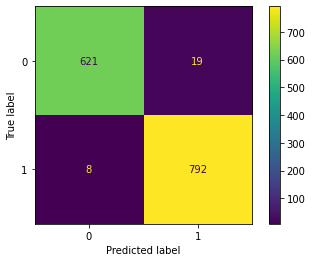

In [ ]:
# show classification report

# extract the predicted probabilities
p_pred = new_model.predict(X_Validation)
p_pred = p_pred.flatten()
#print(p_pred.round(2))
# extract the predicted class labels
y_pred = np.where(p_pred > 0.5, 1, 0)
#print(y_pred)
print(confusion_matrix(y_Validation, y_pred))
print(classification_report(y_Validation, y_pred))

# show confusion matrix
cm = confusion_matrix(y_Validation, y_pred)
cm_display = ConfusionMatrixDisplay(cm).plot()

In [ ]:
########### just for the master thesis some extra runs #########

In [ ]:
print('Numpy', np.__version__)
print('Pandas', pd.__version__)
print('Matplotlib', matplotlib.__version__)
print('Scipy', sc.__version__)
print('Sklearn', skl.__version__)
print('Tensorflow', tf.__version__)
print('H5py', h5py.__version__)

Numpy 1.21.6
Pandas 1.3.5
Matplotlib 3.2.2
Scipy 1.4.1
Sklearn 1.0.2
Tensorflow 2.8.0
H5py 3.1.0


The input shape is: (12320, 3605, 1)
Model: "sequential"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d (Conv1D)                             (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization (BatchNormalization)    (None, 3605, 32)                        128            
                                                                                                    
 conv1d_1 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_1 (BatchNormalization)  (None, 3605, 64)                        256            
                                  

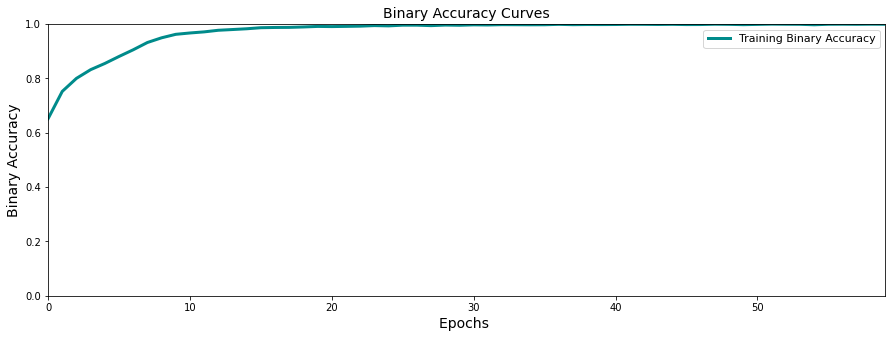

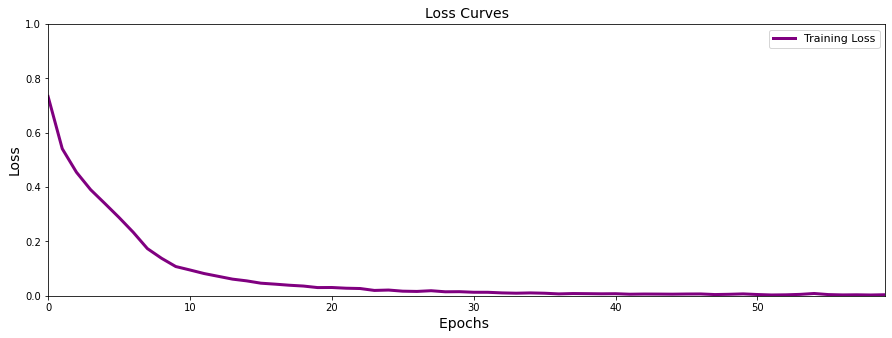

Running time for this model: 29 minute(s) and 33 second(s) (= 1773 seconds).


In [ ]:
# 1D CNN model training with all data (except val set)

start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))

print('The input shape is:', inputs.shape)

epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

model = Sequential()

model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
model.add(BatchNormalization())
model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(AveragePooling1D(pool_size=5))
model.add(BatchNormalization())

model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(AveragePooling1D(pool_size=7))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Flatten())
model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=[metrics.Precision(name='precision'),
              metrics.Recall(name='recall'),
              metrics.BinaryAccuracy(name='binary accuracy'),
              metrics.Accuracy(name='accuracy'),
              metrics.AUC(name='AUC'),
              metrics.FalsePositives(name='false positives'),
              metrics.FalseNegatives(name='false negatives')])

model.summary(line_length = 100)

print("Fit model on training data")

history = model.fit(
    inputs,
    targets,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1
)

# save the model and its weights
model.save('/content/my_saved_model.h5')

# Plot the model 'binary accuracy' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Binary Accuracy', fontsize=14)
plt.title('Binary Accuracy Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()

# Plot the model 'loss' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Loss Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()


end = time.time()
time_needed = int(end-start)

print('Running time for this model: {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))


The input shape is: (12320, 3605, 1)
Training for fold 1 ...
Model: "sequential"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d (Conv1D)                             (None, 3605, 32)                        384            
                                                                                                    
 conv1d_1 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 dropout (Dropout)                           (None, 3605, 64)                        0              
                                                                                                    
 average_pooling1d (AveragePooling1D)        (None, 721, 64)                         0              
          

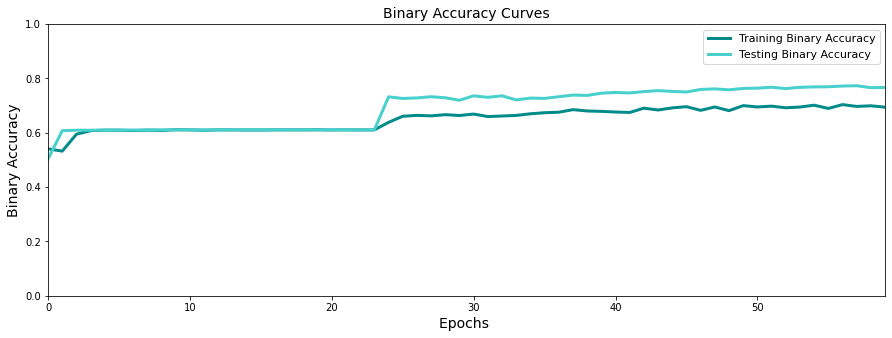

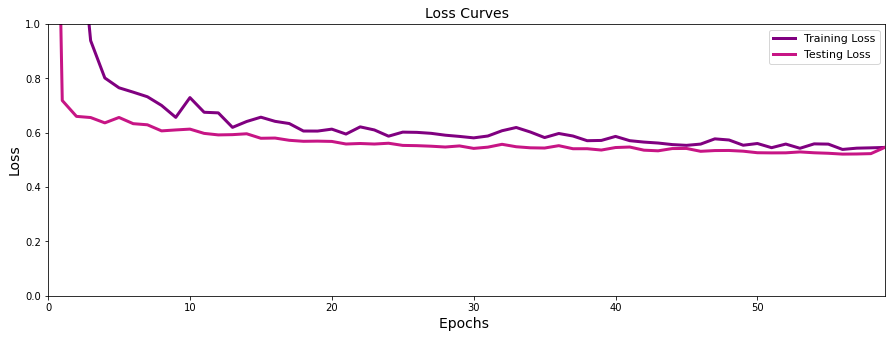

Training for fold 2 ...
Model: "sequential_1"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_4 (Conv1D)                           (None, 3605, 32)                        384            
                                                                                                    
 conv1d_5 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 dropout_3 (Dropout)                         (None, 3605, 64)                        0              
                                                                                                    
 average_pooling1d_2 (AveragePooling1D)      (None, 721, 64)                         0              
                                             

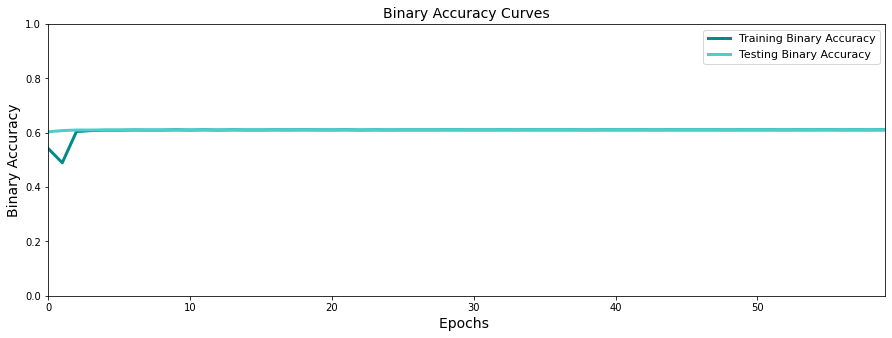

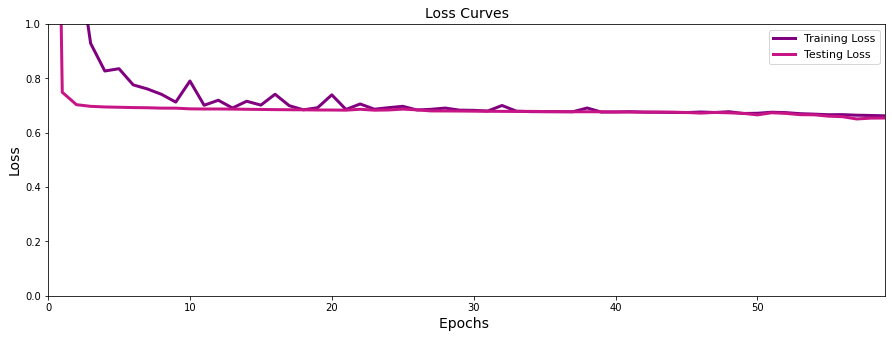

------------------------------------------------------------------------
Score per fold
------------------------------------------------------------------------
> Fold 1 Loss: 0.5464716553688049 | Precision: 0.7766134738922119 | Recall: 0.8670566082000732 | Binary Accuracy: 0.7665584683418274
Accuracy: 0.014285714365541935 | AUC: 0.8380120992660522 | False Neg: 938.0 | False Pos: 500.0
------------------------------------------------------------------------
> Fold 2 Loss: 0.6540783643722534 | Precision: 0.6102272868156433 | Recall: 1.0 | Binary Accuracy: 0.6102272868156433
Accuracy: 0.0 | AUC: 0.5616055130958557 | False Neg: 2401.0 | False Pos: 0.0
------------------------------------------------------------------------
Average scores for all folds:
> Loss: 0.6002750098705292
> Precision: 0.6934203803539276
> Recall: 0.9335283041000366
> Binary Accuracy: 0.6883928775787354 (+- 0.07816559076309204)
> Accuracy: 0.0071428571827709675 (+- 0.0071428571827709675)
> AUC: 0.699808806180954
> F

In [ ]:
# 1D CNN model with K-fold cross validation to test different hyperparameters
# here: Batch Normalization


start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))
print('The input shape is:', inputs.shape)


# K-fold Cross Validation model evaluation
fold_no = 1
num_folds = 2 # here you can decide how many folds you want (in how many pieces the data is split)
epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

# define lists for storing the score values of the different folds
loss_per_fold = []
precision_per_fold = []
recall_per_fold = []
binary_accuracy_per_fold = []
accuracy_per_fold = []
AUC_per_fold = []
false_negatives_per_fold = []
false_positives_per_fold = []


# Define the K-fold Cross Validation
kfold = KFold(n_splits=num_folds, shuffle=True)

for train, test in kfold.split(inputs, targets):

  model = Sequential()

  model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
  #model.add(BatchNormalization())
  model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
  #model.add(BatchNormalization())
  model.add(Dropout(0.2))
  model.add(AveragePooling1D(pool_size=5))
  #model.add(BatchNormalization())

  model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
  #model.add(BatchNormalization())
  model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
  #model.add(BatchNormalization())
  model.add(AveragePooling1D(pool_size=7))
  #model.add(BatchNormalization())
  model.add(Dropout(0.2))

  model.add(Flatten())
  model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
  #model.add(BatchNormalization())
  model.add(Dropout(0.5))
  model.add(Dense(units=1, activation='sigmoid'))

  model.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                loss='binary_crossentropy',
                metrics=[metrics.Precision(name='precision'),
                metrics.Recall(name='recall'),
                metrics.BinaryAccuracy(name='binary accuracy'),
                metrics.Accuracy(name='accuracy'),
                metrics.AUC(name='AUC'),
                metrics.FalsePositives(name='false positives'),
                metrics.FalseNegatives(name='false negatives')])

  print(f'Training for fold {fold_no} ...')
  model.summary(line_length = 100)

  print("Fit model on training data")

  history = model.fit(
      inputs[train],
      targets[train],
      batch_size=batch_size,
      epochs=epochs,
      verbose=1,
      validation_data=(inputs[test], targets[test])
  )

  # Generate generalization metrics
  fold_scores = model.evaluate(inputs[test], targets[test], verbose=0)
  print(f'''
  Test set scores for fold {fold_no}:
                            {model.metrics_names[0]} of {fold_scores[0]};
                            {model.metrics_names[1]} of {fold_scores[1]};
                            {model.metrics_names[2]} of {fold_scores[2]};
                            {model.metrics_names[3]} of {fold_scores[3]};
                            {model.metrics_names[4]} of {fold_scores[4]};
                            {model.metrics_names[5]} of {fold_scores[5]};
                            {model.metrics_names[6]} of {fold_scores[6]};
                            {model.metrics_names[7]} of {fold_scores[7]}

  ''')
  loss_per_fold.append(fold_scores[0])
  precision_per_fold.append(fold_scores[1])
  recall_per_fold.append(fold_scores[2])
  binary_accuracy_per_fold.append(fold_scores[3])
  accuracy_per_fold.append(fold_scores[4])
  AUC_per_fold.append(fold_scores[5])
  false_negatives_per_fold.append(fold_scores[6])
  false_positives_per_fold.append(fold_scores[7])


  # Plot the model 'binary accuracy' graph
  fig = plt.figure(figsize=(15,5))
  plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
  plt.plot(history.history['val_binary accuracy'],'mediumturquoise',linewidth=3.0, label='Testing Binary Accuracy')
  plt.legend(fontsize=11)
  plt.xlabel('Epochs ', fontsize=14)
  plt.ylabel('Binary Accuracy', fontsize=14)
  plt.title('Binary Accuracy Curves', fontsize=14)
  plt.ylim([0.0, 1.0])
  plt.xlim([0, epochs-1])
  plt.show()

  # Plot the model 'loss' graph
  fig = plt.figure(figsize=(15,5))
  plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
  plt.plot(history.history['val_loss'],'mediumvioletred',linewidth=3.0, label='Testing Loss')
  plt.legend(fontsize=11)
  plt.xlabel('Epochs ', fontsize=14)
  plt.ylabel('Loss', fontsize=14)
  plt.title('Loss Curves', fontsize=14)
  plt.ylim([0.0, 1.0])
  plt.xlim([0, epochs-1])
  plt.show()
  # Increase fold number
  fold_no = fold_no + 1

# == Provide average scores ==
print('------------------------------------------------------------------------')
print('Score per fold')
for i in range(0, len(accuracy_per_fold)):
  print('------------------------------------------------------------------------')
  print(f'> Fold {i+1} Loss: {loss_per_fold[i]} | Precision: {precision_per_fold[i]} | Recall: {recall_per_fold[i]} | Binary Accuracy: {binary_accuracy_per_fold[i]}')
  print(f'Accuracy: {accuracy_per_fold[i]} | AUC: {AUC_per_fold[i]} | False Neg: {false_negatives_per_fold[i]} | False Pos: {false_positives_per_fold[i]}')
print('------------------------------------------------------------------------')
print('Average scores for all folds:')
print(f'> Loss: {np.mean(loss_per_fold)}')
print(f'> Precision: {np.mean(precision_per_fold)}')
print(f'> Recall: {np.mean(recall_per_fold)}')
print(f'> Binary Accuracy: {np.mean(binary_accuracy_per_fold)} (+- {np.std(binary_accuracy_per_fold)})')
print(f'> Accuracy: {np.mean(accuracy_per_fold)} (+- {np.std(accuracy_per_fold)})')
print(f'> AUC: {np.mean(AUC_per_fold)}')
print(f'> False Neg: {np.mean(false_negatives_per_fold)}')
print(f'> False Pos: {np.mean(false_positives_per_fold)}')
print('------------------------------------------------------------------------')


end = time.time()
time_needed = int(end-start)

print('Running time for this model (for all folds): {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))


The input shape is: (12320, 3605, 1)
Training for fold 1 ...
Model: "sequential_2"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_8 (Conv1D)                           (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization (BatchNormalization)    (None, 3605, 32)                        128            
                                                                                                    
 conv1d_9 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_1 (BatchNormalization)  (None, 3605, 64)                        256            
        

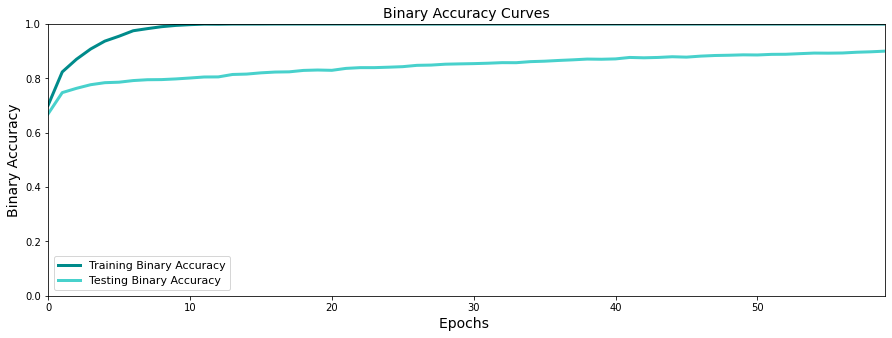

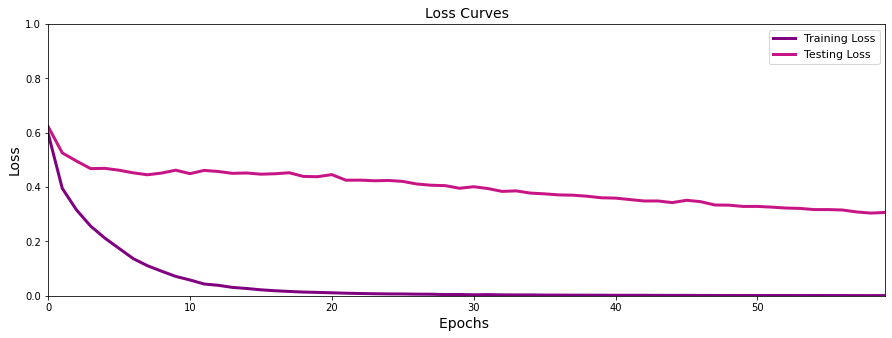

Training for fold 2 ...
Model: "sequential_3"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_12 (Conv1D)                          (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization_7 (BatchNormalization)  (None, 3605, 32)                        128            
                                                                                                    
 conv1d_13 (Conv1D)                          (None, 3605, 64)                        22592          
                                                                                                    
 batch_normalization_8 (BatchNormalization)  (None, 3605, 64)                        256            
                                             

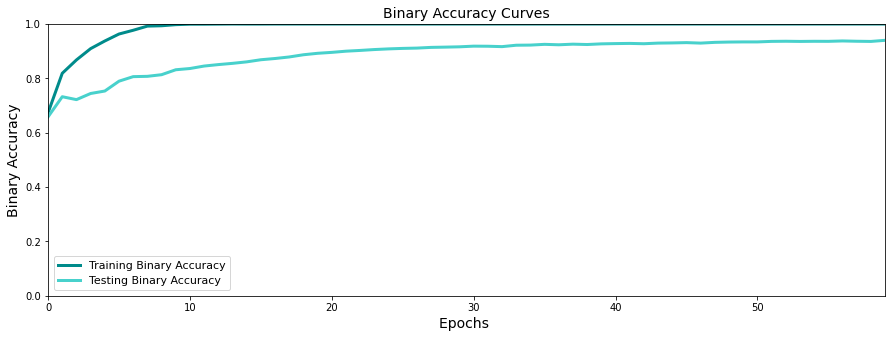

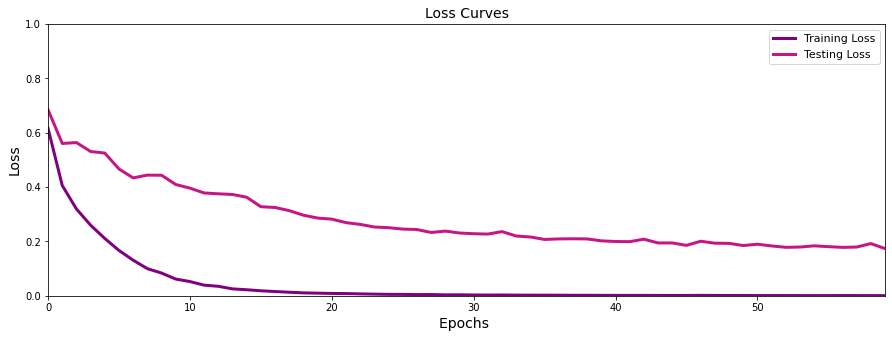

------------------------------------------------------------------------
Score per fold
------------------------------------------------------------------------
> Fold 1 Loss: 0.3065996766090393 | Precision: 0.9160857796669006 | Recall: 0.9187953472137451 | Binary Accuracy: 0.9001623392105103
Accuracy: 0.0009740259847603738 | AUC: 0.9578462243080139 | False Neg: 313.0 | False Pos: 302.0
------------------------------------------------------------------------
> Fold 2 Loss: 0.1737799048423767 | Precision: 0.9468611478805542 | Recall: 0.9563272595405579 | Binary Accuracy: 0.9399350881576538
Accuracy: 0.00016233765927609056 | AUC: 0.9832192659378052 | False Neg: 204.0 | False Pos: 166.0
------------------------------------------------------------------------
Average scores for all folds:
> Loss: 0.240189790725708
> Precision: 0.9314734637737274
> Recall: 0.9375613033771515
> Binary Accuracy: 0.920048713684082 (+- 0.019886374473571777)
> Accuracy: 0.0005681818220182322 (+- 0.00040584416274

In [ ]:
# 1D CNN model with K-fold cross validation to test different hyperparameters
# here: Dropout


start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))
print('The input shape is:', inputs.shape)


# K-fold Cross Validation model evaluation
fold_no = 1
num_folds = 2 # here you can decide how many folds you want (in how many pieces the data is split)
epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

# define lists for storing the score values of the different folds
loss_per_fold = []
precision_per_fold = []
recall_per_fold = []
binary_accuracy_per_fold = []
accuracy_per_fold = []
AUC_per_fold = []
false_negatives_per_fold = []
false_positives_per_fold = []


# Define the K-fold Cross Validation
kfold = KFold(n_splits=num_folds, shuffle=True)

for train, test in kfold.split(inputs, targets):

  model = Sequential()

  model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
  model.add(BatchNormalization())
  model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
  model.add(BatchNormalization())
  #model.add(Dropout(0.2))
  model.add(AveragePooling1D(pool_size=5))
  model.add(BatchNormalization())

  model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
  model.add(BatchNormalization())
  model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
  model.add(BatchNormalization())
  model.add(AveragePooling1D(pool_size=7))
  model.add(BatchNormalization())
  #model.add(Dropout(0.2))

  model.add(Flatten())
  model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
  model.add(BatchNormalization())
  #model.add(Dropout(0.5))
  model.add(Dense(units=1, activation='sigmoid'))

  model.compile(
                optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                loss='binary_crossentropy',
                metrics=[metrics.Precision(name='precision'),
                metrics.Recall(name='recall'),
                metrics.BinaryAccuracy(name='binary accuracy'),
                metrics.Accuracy(name='accuracy'),
                metrics.AUC(name='AUC'),
                metrics.FalsePositives(name='false positives'),
                metrics.FalseNegatives(name='false negatives')])

  print(f'Training for fold {fold_no} ...')
  model.summary(line_length = 100)

  print("Fit model on training data")

  history = model.fit(
      inputs[train],
      targets[train],
      batch_size=batch_size,
      epochs=epochs,
      verbose=1,
      validation_data=(inputs[test], targets[test])
  )

  # Generate generalization metrics
  fold_scores = model.evaluate(inputs[test], targets[test], verbose=0)
  print(f'''
  Test set scores for fold {fold_no}:
                            {model.metrics_names[0]} of {fold_scores[0]};
                            {model.metrics_names[1]} of {fold_scores[1]};
                            {model.metrics_names[2]} of {fold_scores[2]};
                            {model.metrics_names[3]} of {fold_scores[3]};
                            {model.metrics_names[4]} of {fold_scores[4]};
                            {model.metrics_names[5]} of {fold_scores[5]};
                            {model.metrics_names[6]} of {fold_scores[6]};
                            {model.metrics_names[7]} of {fold_scores[7]}

  ''')
  loss_per_fold.append(fold_scores[0])
  precision_per_fold.append(fold_scores[1])
  recall_per_fold.append(fold_scores[2])
  binary_accuracy_per_fold.append(fold_scores[3])
  accuracy_per_fold.append(fold_scores[4])
  AUC_per_fold.append(fold_scores[5])
  false_negatives_per_fold.append(fold_scores[6])
  false_positives_per_fold.append(fold_scores[7])


  # Plot the model 'binary accuracy' graph
  fig = plt.figure(figsize=(15,5))
  plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
  plt.plot(history.history['val_binary accuracy'],'mediumturquoise',linewidth=3.0, label='Testing Binary Accuracy')
  plt.legend(fontsize=11)
  plt.xlabel('Epochs ', fontsize=14)
  plt.ylabel('Binary Accuracy', fontsize=14)
  plt.title('Binary Accuracy Curves', fontsize=14)
  plt.ylim([0.0, 1.0])
  plt.xlim([0, epochs-1])
  plt.show()

  # Plot the model 'loss' graph
  fig = plt.figure(figsize=(15,5))
  plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
  plt.plot(history.history['val_loss'],'mediumvioletred',linewidth=3.0, label='Testing Loss')
  plt.legend(fontsize=11)
  plt.xlabel('Epochs ', fontsize=14)
  plt.ylabel('Loss', fontsize=14)
  plt.title('Loss Curves', fontsize=14)
  plt.ylim([0.0, 1.0])
  plt.xlim([0, epochs-1])
  plt.show()
  # Increase fold number
  fold_no = fold_no + 1

# == Provide average scores ==
print('------------------------------------------------------------------------')
print('Score per fold')
for i in range(0, len(accuracy_per_fold)):
  print('------------------------------------------------------------------------')
  print(f'> Fold {i+1} Loss: {loss_per_fold[i]} | Precision: {precision_per_fold[i]} | Recall: {recall_per_fold[i]} | Binary Accuracy: {binary_accuracy_per_fold[i]}')
  print(f'Accuracy: {accuracy_per_fold[i]} | AUC: {AUC_per_fold[i]} | False Neg: {false_negatives_per_fold[i]} | False Pos: {false_positives_per_fold[i]}')
print('------------------------------------------------------------------------')
print('Average scores for all folds:')
print(f'> Loss: {np.mean(loss_per_fold)}')
print(f'> Precision: {np.mean(precision_per_fold)}')
print(f'> Recall: {np.mean(recall_per_fold)}')
print(f'> Binary Accuracy: {np.mean(binary_accuracy_per_fold)} (+- {np.std(binary_accuracy_per_fold)})')
print(f'> Accuracy: {np.mean(accuracy_per_fold)} (+- {np.std(accuracy_per_fold)})')
print(f'> AUC: {np.mean(AUC_per_fold)}')
print(f'> False Neg: {np.mean(false_negatives_per_fold)}')
print(f'> False Pos: {np.mean(false_positives_per_fold)}')
print('------------------------------------------------------------------------')


end = time.time()
time_needed = int(end-start)

print('Running time for this model (for all folds): {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))


The input shape is: (12320, 3605, 1)
Model: "sequential"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d (Conv1D)                             (None, 3605, 32)                        384            
                                                                                                    
 conv1d_1 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 dropout (Dropout)                           (None, 3605, 64)                        0              
                                                                                                    
 average_pooling1d (AveragePooling1D)        (None, 721, 64)                         0              
                                  

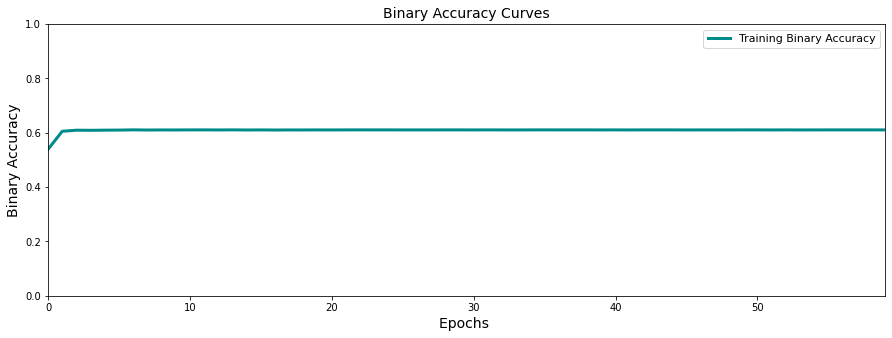

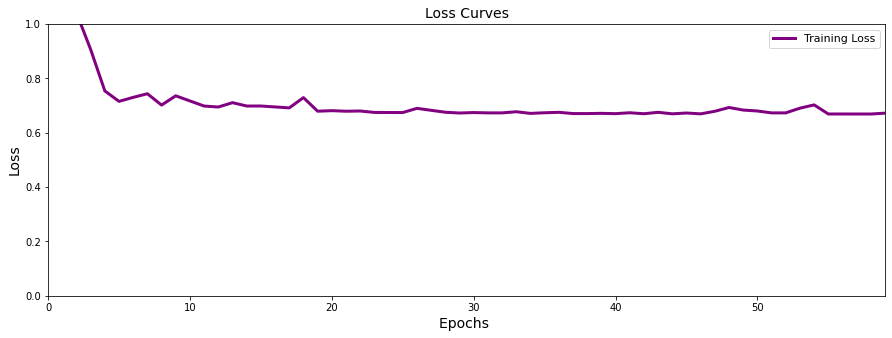

Running time for this model: 24 minute(s) and 29 second(s) (= 1469 seconds).


In [ ]:
# 1D CNN model training with all data (except val set) and no batch normalization

start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))

print('The input shape is:', inputs.shape)

epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

model = Sequential()

model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
#model.add(BatchNormalization())
model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
#model.add(BatchNormalization())
model.add(Dropout(0.2))
model.add(AveragePooling1D(pool_size=5))
#model.add(BatchNormalization())

model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
#model.add(BatchNormalization())
model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
#model.add(BatchNormalization())
model.add(AveragePooling1D(pool_size=7))
#model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Flatten())
model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
#model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(units=1, activation='sigmoid'))

model.compile(
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=[metrics.Precision(name='precision'),
              metrics.Recall(name='recall'),
              metrics.BinaryAccuracy(name='binary accuracy'),
              metrics.Accuracy(name='accuracy'),
              metrics.AUC(name='AUC'),
              metrics.FalsePositives(name='false positives'),
              metrics.FalseNegatives(name='false negatives')])

model.summary(line_length = 100)

print("Fit model on training data")

history = model.fit(
    inputs,
    targets,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1
)

# save the model and its weights
model.save('/content/my_saved_model.h5')

# Plot the model 'binary accuracy' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Binary Accuracy', fontsize=14)
plt.title('Binary Accuracy Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()

# Plot the model 'loss' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Loss Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()


end = time.time()
time_needed = int(end-start)

print('Running time for this model: {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))


The input shape is: (12320, 3605, 1)
Model: "sequential_1"
____________________________________________________________________________________________________
 Layer (type)                                Output Shape                            Param #        
 conv1d_4 (Conv1D)                           (None, 3605, 32)                        384            
                                                                                                    
 batch_normalization (BatchNormalization)    (None, 3605, 32)                        128            
                                                                                                    
 conv1d_5 (Conv1D)                           (None, 3605, 64)                        22592          
                                                                                                    
 dropout_3 (Dropout)                         (None, 3605, 64)                        0              
                                

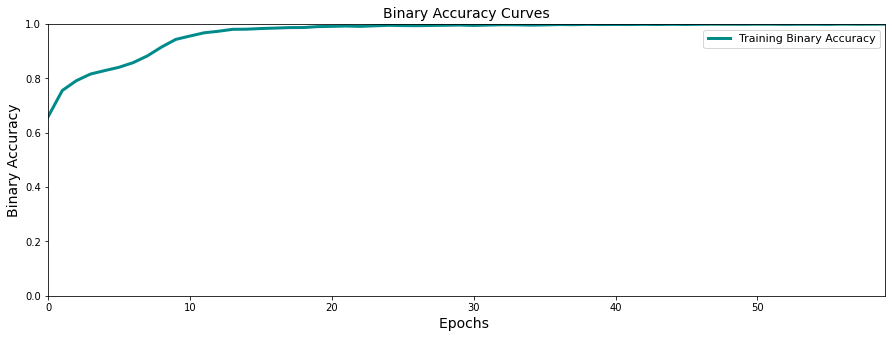

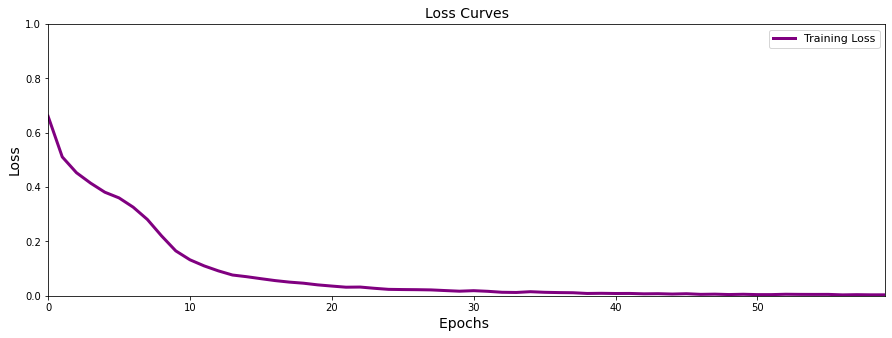

Running time for this model: 39 minute(s) and 26 second(s) (= 2366 seconds).


In [ ]:
# 1D CNN model training with all data (except val set) and batch normalization after dropout

start = time.time()

inputs = X
targets = y
inputs = np.asarray(inputs).astype('float32').reshape(inputs.shape[0], inputs.shape[1], 1)
targets = np.asarray(targets).astype('float32').reshape((-1,1))

print('The input shape is:', inputs.shape)

epochs = 60
batch_size = 100 # x windows of data will be exposed to the model before the weights of the model are updated

model = Sequential()

model.add(Convolution1D(filters=32, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu', input_shape=(inputs.shape[1],1)))
model.add(BatchNormalization())
model.add(Convolution1D(filters=64, kernel_size=11, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(Dropout(0.2))
model.add(BatchNormalization())
model.add(AveragePooling1D(pool_size=5))
model.add(BatchNormalization())

model.add(Convolution1D(filters=128, kernel_size=9, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(Convolution1D(filters=256, kernel_size=7, padding='same', kernel_initializer='random_normal', activation='relu'))
model.add(BatchNormalization())
model.add(AveragePooling1D(pool_size=7))
model.add(Dropout(0.2))
model.add(BatchNormalization())


model.add(Flatten())
model.add(Dense(units=103, kernel_initializer='normal', activation='relu'))
model.add(Dropout(0.5))
model.add(BatchNormalization())
model.add(Dense(units=1, activation='sigmoid'))

model.compile(
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=[metrics.Precision(name='precision'),
              metrics.Recall(name='recall'),
              metrics.BinaryAccuracy(name='binary accuracy'),
              metrics.Accuracy(name='accuracy'),
              metrics.AUC(name='AUC'),
              metrics.FalsePositives(name='false positives'),
              metrics.FalseNegatives(name='false negatives')])

model.summary(line_length = 100)

print("Fit model on training data")

history = model.fit(
    inputs,
    targets,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1
)

# save the model and its weights
model.save('/content/my_saved_model.h5')

# Plot the model 'binary accuracy' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['binary accuracy'],'darkcyan',linewidth=3.0, label='Training Binary Accuracy')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Binary Accuracy', fontsize=14)
plt.title('Binary Accuracy Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()

# Plot the model 'loss' graph
fig = plt.figure(figsize=(15,5))
plt.plot(history.history['loss'],'purple',linewidth=3.0, label='Training Loss')
plt.legend(fontsize=11)
plt.xlabel('Epochs ', fontsize=14)
plt.ylabel('Loss', fontsize=14)
plt.title('Loss Curves', fontsize=14)
plt.ylim([0.0, 1.0])
plt.xlim([0, epochs-1])
plt.show()


end = time.time()
time_needed = int(end-start)

print('Running time for this model: {} minute(s) and {} second(s) (= {} seconds).'.format(int(time_needed/60), time_needed%60, time_needed))
